# Tutorial 4. Cross validation

PE1333 Machine Learning para Economistas. Maestría en Economía, UdeSA. 22 de octubre de 2026.

Un modelo que ajusta muy bien dentro de la muestra puede predecir mal fuera de ella. Para elegir la complejidad de un modelo (el grado de un polinomio o la cantidad de vecinos $K$) necesitamos estimar el error fuera de la muestra sin usar la base de testeo. Eso es lo que hace cross validation.

Las secciones 1 a 4 usan la base `Auto` de [ISLP](https://islp.readthedocs.io/en/latest/datasets/Auto.html). La sección 5 vuelve a la base `Default` del Tutorial 3 y elige la cantidad de vecinos por cross validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

AZUL = "#0F285A"
DORADO = "#AA8448"
GRIS_AZUL = "#607896"

pd.set_option("display.float_format", lambda x: "%.3f" % x)

## 1. Los datos

`Auto` tiene información de 392 autos. Vamos a predecir el rendimiento, `mpg` (millas por galón), con la potencia del motor, `horsepower` (caballos de fuerza).

In [2]:
auto = pd.read_csv("datos/Auto.csv")

print("Dimensión:", auto.shape)
print("Duplicados:", auto.duplicated().sum())
print("Faltantes:", auto.isna().sum().sum())
auto[["mpg", "horsepower"]].describe()

Dimensión: (392, 9)
Duplicados: 0
Faltantes: 0


,mpg,horsepower
count,392.000,392.000
mean,23.446,104.469
std,7.805,38.491
min,9.000,46.000
25%,17.000,75.000
50%,22.750,93.500
75%,29.000,126.000
max,46.600,230.000


## 2. Entrenamiento y testeo

Partimos la base en entrenamiento (70%) y testeo (30%) con la semilla 444. La base de testeo la guardamos para el final y no la usamos para elegir nada.

In [3]:
y = auto["mpg"].values
X = auto[["horsepower"]].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=444)
print("entrenamiento:", len(y_train), "  testeo:", len(y_test))

entrenamiento: 274   testeo: 118


Siempre conviene chequear que la partición sea realmente aleatoria. Una forma es una tabla de diferencia de medias entre entrenamiento y testeo.

In [4]:
balance = pd.DataFrame({
    "media train": [X_train.mean(), y_train.mean()],
    "media test": [X_test.mean(), y_test.mean()],
    "p-valor": [stats.ttest_ind(X_train.ravel(), X_test.ravel()).pvalue, stats.ttest_ind(y_train, y_test).pvalue],
}, index=["horsepower", "mpg"])
balance

,media train,media test,p-valor
horsepower,103.752,106.136,0.574
mpg,23.503,23.313,0.825


Los dos p-valores son altos: no hay evidencia de que las medias de entrenamiento y testeo sean distintas.

## 3. Enfoque de validación

Para elegir el modelo sin tocar el testeo, partimos otra vez la base de entrenamiento: estimamos con el 70% y medimos el error en el 30% restante, que llamamos base de validación.

Empezamos con una regresión lineal y comparamos el ajuste adentro y afuera de la muestra.

In [5]:
X_e, X_v, y_e, y_v = train_test_split(X_train, y_train, test_size=0.3, random_state=1)

lreg = LinearRegression().fit(X_e, y_e)

print("R2 adentro de la muestra:", round(r2_score(y_e, lreg.predict(X_e)), 3))
print("R2 afuera de la muestra:", round(r2_score(y_v, lreg.predict(X_v)), 3))
print("ECM adentro de la muestra:", round(mean_squared_error(y_e, lreg.predict(X_e)), 2))
print("ECM afuera de la muestra:", round(mean_squared_error(y_v, lreg.predict(X_v)), 2))

R2 adentro de la muestra: 0.621
R2 afuera de la muestra: 0.56
ECM adentro de la muestra: 22.23
ECM afuera de la muestra: 23.44


Afuera de la muestra el modelo se equivoca más (T4.10). El $R^2$ y el ECM de entrenamiento miden qué tan bien el modelo sigue los datos con los que se estimó, y eso no es lo que queremos.

Ahora probamos polinomios de grado 1 a 10. `PolynomialFeatures` arma las columnas $X, X^2, \ldots, X^{grado}$ y después estimamos por MCO. Armamos una función para no repetir el código.

In [6]:
def polinomio(grado):
    '''
    Regresión polinómica: transforma X en X, X^2, ..., X^grado y estima por MCO.
    Input: grado del polinomio
    Output: modelo sin estimar
    '''
    # include_bias=False porque la constante ya la agrega LinearRegression
    return make_pipeline(PolynomialFeatures(grado, include_bias=False), LinearRegression())


def ecm_validacion(semilla):
    '''
    Parte la base de entrenamiento en 70% y 30%, estima polinomios de grado 1 a 10 y calcula el ECM en el 30%.
    Input: semilla de la partición
    Output: ECM de validación para cada grado
    '''
    X_e, X_v, y_e, y_v = train_test_split(X_train, y_train, test_size=0.3, random_state=semilla)
    ecm = [mean_squared_error(y_v, polinomio(g).fit(X_e, y_e).predict(X_v)) for g in range(1, 11)]
    return pd.Series(ecm, index=pd.Index(range(1, 11), name="grado"), name="ECM validación")

In [7]:
ecm_1 = ecm_validacion(1)
print("grado elegido:", ecm_1.idxmin())
ecm_1

grado elegido: 2


grado
1    23.439
2    22.716
3    23.673
4    23.610
5    23.263
6    23.374
7    23.226
8    22.940
9    22.957
10   23.528
Name: ECM validación, dtype: float64

### Enfoque de validación con una nueva partición

Repetimos lo mismo, pero con otra partición de la base de entrenamiento.

In [8]:
ecm_0 = ecm_validacion(0)
print("grado elegido:", ecm_0.idxmin())
pd.concat({"partición 1": ecm_1, "partición 2": ecm_0}, axis=1)

grado elegido: 7


,partición 1,partición 2
grado,,
1,23.439,29.751
2,22.716,25.910
3,23.673,25.347
4,23.610,25.324
5,23.263,25.185
6,23.374,25.344
7,23.226,25.112
8,22.940,27.862
9,22.957,40.075


Con la primera partición se elige grado 2 y con la segunda grado 7. El nivel del error también cambia. El ECM depende de qué observaciones quedaron en cada parte, así que con una sola partición la elección depende del sorteo.

## 4. K-fold cross validation

Es una técnica de remuestreo para estimar el error fuera de la muestra. Sirve para elegir la complejidad del modelo y para estimar cuánto se va a equivocar con datos nuevos.

Consiste en:

- partir la base de entrenamiento al azar en $K$ bloques del mismo tamaño,
- estimar el modelo $K$ veces, cada vez dejando afuera un bloque distinto, y calcular el error en el bloque que quedó afuera,
- promediar los $K$ errores.

Cada bloque se usa una vez para validar y $K - 1$ veces para estimar. Lo usual es $K = 5$ o $K = 10$.

```
bloque 1:  V E E E E
bloque 2:  E V E E E
bloque 3:  E E V E E
bloque 4:  E E E V E
bloque 5:  E E E E V
```

Usamos [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) de scikit-learn. Partimos solo `X_train`, la base de testeo no entra.

In [9]:
particiones = KFold(n_splits=5, shuffle=True, random_state=444)

filas = []
for grado in range(1, 11):
    # split da los índices de las observaciones para estimar y para validar en cada bloque
    for bloque, (estima, valida) in enumerate(particiones.split(X_train), start=1):
        modelo = polinomio(grado).fit(X_train[estima], y_train[estima])
        ecm = mean_squared_error(y_train[valida], modelo.predict(X_train[valida]))
        filas.append({"grado": grado, "bloque": bloque, "ECM": ecm})

cv = pd.DataFrame(filas)
cv.head(10)

,grado,bloque,ECM
0,1,1,31.690
1,1,2,17.227
2,1,3,20.424
3,1,4,21.822
4,1,5,24.155
5,2,1,25.479
6,2,2,11.846
7,2,3,17.889
8,2,4,19.055
9,2,5,19.297


### ¿Cómo elegimos el modelo?

Una opción es mirar los ECM de cada bloque en un boxplot.

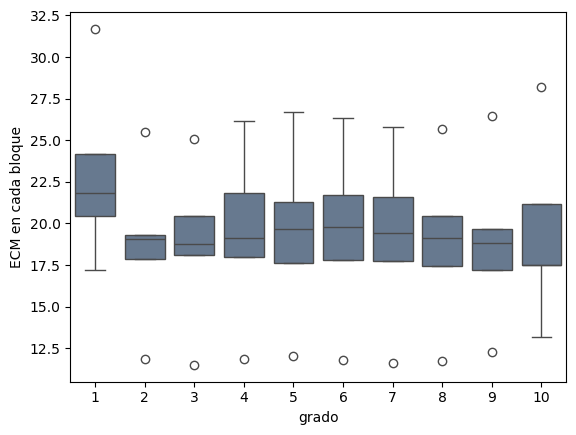

In [10]:
sns.boxplot(data=cv, x="grado", y="ECM", color=GRIS_AZUL)
plt.ylabel("ECM en cada bloque")
plt.show()

La dispersión dentro de cada grado es mucho más grande que la diferencia entre grados. Qué observaciones tocaron en cada bloque pesa más que el grado del polinomio, y por eso promediamos.

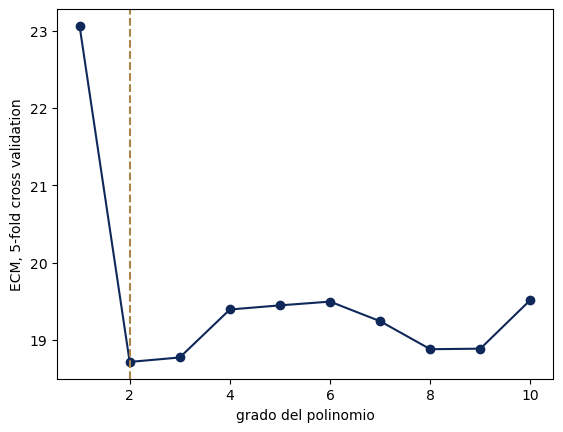

El mínimo error es 18.71 y se da con un polinomio de grado 2


In [11]:
# error de cross validation: el promedio de los 5 bloques para cada grado
cv_grado = cv.groupby("grado")["ECM"].mean()
grado_cv = cv_grado.idxmin()

plt.plot(cv_grado.index, cv_grado.values, marker="o", color=AZUL)
plt.axvline(grado_cv, color=DORADO, linestyle="--")
plt.xlabel("grado del polinomio")
plt.ylabel("ECM, 5-fold cross validation")
plt.show()

print("El mínimo error es", round(cv_grado.min(), 2), "y se da con un polinomio de grado", grado_cv)

Es el mismo procedimiento del gráfico de los vinos de Walter (T4.15): para cada grado calculamos el error de cross validation y elegimos el mínimo. Acá el mínimo está en el grado 2, y del grado 2 al 10 la curva es casi plana.

### El modelo final

Los cinco modelos de cross validation sirven solo para medir el error. El modelo final se estima una vez más, con toda la base de entrenamiento y el grado elegido, y recién ahí miramos la base de testeo (T4.13).

ECM de testeo, grado 2: 20.9


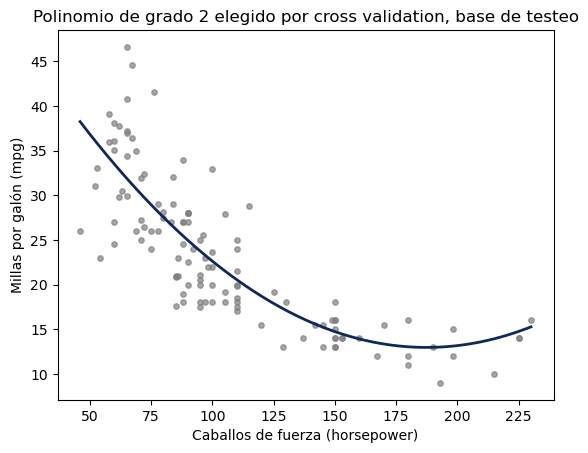

In [12]:
final = polinomio(grado_cv).fit(X_train, y_train)
print(f"ECM de testeo, grado {grado_cv}:", round(mean_squared_error(y_test, final.predict(X_test)), 2))

grilla = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
plt.scatter(X_test, y_test, color="gray", s=15, alpha=0.7)
plt.plot(grilla, final.predict(grilla), color=AZUL, linewidth=2)
plt.xlabel("Caballos de fuerza (horsepower)")
plt.ylabel("Millas por galón (mpg)")
plt.title(f"Polinomio de grado {grado_cv} elegido por cross validation, base de testeo")
plt.show()

## 5. Elegir $K$ en vecinos cercanos

En el Tutorial 3 usamos vecinos cercanos con $K = 25$, fijado de antemano. Ahora lo elegimos por cross validation con la base `Default`. Los pasos son los mismos que en la sección 4, con dos cambios:

- medimos el *accuracy*, la proporción de aciertos, y nos quedamos con el más alto,
- estandarizamos las variables con la media y el desvío de la base de entrenamiento, porque vecinos cercanos usa distancias.

Hay dos $K$ distintos: el de los bloques de cross validation, que es 5, y el de vecinos cercanos, que es el que elegimos.

In [13]:
df = pd.read_csv("datos/Default.csv")
df["incumple"] = (df["default"] == "Yes").astype(int)
df["estudiante"] = (df["student"] == "Yes").astype(int)
df["saldo"] = df["balance"]
df["ingreso"] = df["income"] / 1000

Xd = df[["saldo", "ingreso", "estudiante"]]
yd = df["incumple"].values
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, random_state=444, stratify=yd)

# la media y el desvío salen solo de entrenamiento y se aplican a las dos bases
escala = StandardScaler().fit(Xd_train)
Z_train = escala.transform(Xd_train)
Z_test = escala.transform(Xd_test)

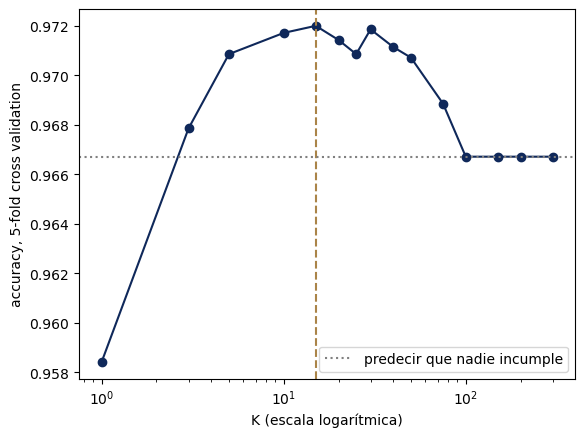

K elegido: 15


K,1,3,5,10,15,20,25,30,40,50,75,100,150,200,300
accuracy,0.958,0.968,0.971,0.972,0.972,0.971,0.971,0.972,0.971,0.971,0.969,0.967,0.967,0.967,0.967


In [14]:
grilla_k = [1, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 300]

filas = []
for k in grilla_k:
    for bloque, (estima, valida) in enumerate(particiones.split(Z_train), start=1):
        knn = KNeighborsClassifier(n_neighbors=k).fit(Z_train[estima], yd_train[estima])
        acc = accuracy_score(yd_train[valida], knn.predict(Z_train[valida]))
        filas.append({"K": k, "bloque": bloque, "accuracy": acc})

accuracy_k = pd.DataFrame(filas).groupby("K")["accuracy"].mean()
k_cv = accuracy_k.idxmax()
nadie_incumple = 1 - yd_train.mean()

plt.plot(accuracy_k.index, accuracy_k.values, marker="o", color=AZUL)
plt.axvline(k_cv, color=DORADO, linestyle="--")
plt.axhline(nadie_incumple, color="gray", linestyle=":", label="predecir que nadie incumple")
plt.xscale("log")
plt.xlabel("K (escala logarítmica)")
plt.ylabel("accuracy, 5-fold cross validation")
plt.legend()
plt.show()

print("K elegido:", k_cv)
accuracy_k.to_frame().T

- Con $K = 1$ el clasificador copia al vecino más parecido y es muy variable. A medida que $K$ crece, el accuracy sube, llega a un máximo y después baja.
- La grilla llega hasta donde la curva deja de mejorar. Desde $K = 100$ el accuracy queda en 0,967: con tantos vecinos casi nunca hay mayoría de incumplidores y el clasificador predice que nadie incumple. Es el mismo accuracy que se obtiene sin mirar ninguna variable, porque en `Default` incumple el 3,3%.
- Entre $K = 5$ y $K = 50$ la curva es casi plana, como pasaba con el polinomio.

Con el $K$ elegido estimamos una vez con toda la base de entrenamiento y evaluamos en testeo.

In [15]:
knn_cv = KNeighborsClassifier(n_neighbors=k_cv).fit(Z_train, yd_train)
print(f"accuracy de testeo, K = {k_cv}:", round(accuracy_score(yd_test, knn_cv.predict(Z_test)), 4))
print("accuracy de testeo prediciendo que nadie incumple:", round(1 - yd_test.mean(), 4))

accuracy de testeo, K = 15: 0.9733
accuracy de testeo prediciendo que nadie incumple: 0.9667
